# 01 — Did the intended strains land in the wells, and what else is in them?

**Run:** 20261112 flowcell, demultiplexed into `20261112_demux`. Sequenced: passage
plates 5 and 6 at 24 h and at 5 d = **barcode plates 5, 6, 9, 10** (layout `plate` is
the barcode plate; `culture_plate` / `timepoint` say which culture and when). Every
other barcode plate on the sheet (1–4, 7, 8, 11, 12) and the decoys (99) were never
PCR'd: whatever lands there was put there by the demultiplexer, which makes them the
run's negative control.

**Reference:** `reference_db_20260907_haplotypes.fasta` (one entry per operon haplotype,
base-exact spoa consensus from 20260907).

**How each read is called** (`community_qc.assign`, details in section 2): distance to
the nearest haplotype of an *expected member*, and to the nearest haplotype of *any
other* strain. Ties go to the member (254/378 reference strains have a byte-identical
16S twin; an open search would file half of M19's reads under its twin M15 as
"contamination"). A read is **near** a reference if it is within 12 bp + 2× its expected
error count; otherwise it is **unexplained** (chimera, or sequence the DB doesn't hold).

Everything below reads `outputs/` (scripts `q01`–`q05`; `python run_all.py` rebuilds).

In [1]:
import sys, json
from pathlib import Path
QC_DIR = Path("/home/rl/scripts/karl/sequencing_experiments/community_assembly_experiments/20261026/02_qc")
sys.path.insert(0, str(QC_DIR))
import config                                   # paths; puts the shared libraries on sys.path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from community_qc import plots as P, composition as comp, io as cio
P.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
OUT, FIG = config.OUT, config.FIG
TH = json.load(open(OUT / "q02_thresholds.json"))
lay = cio.load_layout(config.LAYOUT_CSV)
def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

ws = pd.read_csv(OUT / "q04_well_summary.csv")
mt = pd.read_csv(OUT / "q04_member_table.csv")
fo = pd.read_csv(OUT / "q04_foreign.csv")
fl = pd.read_csv(OUT / "q04_well_flags.csv")
st = pd.read_csv(OUT / "q01_well_read_stats.csv")
SEQ = config.SEQUENCED_PLATES
TP = {5: "plate 5 · 24 h", 6: "plate 6 · 24 h", 9: "plate 5 · 5 d", 10: "plate 6 · 5 d"}

## Summary (numbers reproduced in the sections below)

**The strains are what we think they are.** 99.5% of member read groups (well × strain,
≥ 10 reads; 97.7% identical, the rest at het sites) match their 20260907 reference to
within 2 bp at consensus level. No label scramble like 20260721's.

**Almost every strain landed, with three exceptions.** On the deep 24 h plate (5), 74
of 75 strains are seen in their wells. **K11 (0/51 wells), I8 (3/45) and B17 (6/39)**
are missing on both deep plates. K11 and I8 had the lowest source OD (0.14), so the
source well was probably near-empty. B17's source grew (OD 2.7) but B17 does not
establish. Detection is consistent across replicates: of 811 (community, member) cells
in triplicate on plate 5, 539 are seen in all three and 67 in none.

**Some source wells hold a second organism, which travels with its member from 24 h
on.** **M19** brings an organism the reference doesn't contain (U001, 43 bp from
anything; in 43/43 of its 5 d wells only alongside M19) plus E14. **F17** brings F7
(54/57 wells), **F14** brings F2, **G2** brings H8, and **N15** brings N23/O3.
Treat these as part of the inoculum, not as contamination.

**Plates 6 and 9: weak PCR plus contaminating DNA.** They are ~20× shallower than 5 and
10, and ~30% of their reads come from strains *never inoculated in this experiment*
(A13, A10, A16, L6, M12, …). Every well gets roughly the same number of these reads
(~6–15) whatever its depth, and the two plates share one profile strain for strain
(Spearman 0.87) although they hold different cultures. That fits contaminating 16S DNA
entering at the PCR, which dominates when the real template is weak. **Re-run 6 and 9
with fresh reagents and a no-template control.**

**Demultiplexing ran at -e 6** (the config key is misspelled, so the pipeline's
default applied). Measured on the never-PCR'd plates, 0.63% of reads are mis-assigned:
~0.15% of a deep well, ~3% (10% at the 90th percentile) of a shallow one. Foreign
calls are corrected for it. Re-demultiplexing at `-e 4` would cut it ~4×.

**Contamination at 5 d is real and growing.** On the deep 5 d plate (plate 6 @ 5 d), 28%
of wells hold ≥ 5% foreign reads. Foreign strains sit in an **adjacent well's
community 1.3–1.5× more often than chance at 5 d (p ≤ 0.002), and not at all at 24 h**,
so well-to-well transfer comes from passaging. **G4** spreads between wells of plate
6, and the **A1/A4/A6** organism, inoculated only on main plates 1–4, has crossed
between plates. Blank 6-J11 holds 2,250 reads of exactly these at 5 d while its OD is
still at baseline. By OD the blanks start growing from d6–7 on the passage plates
(11/12 blanks across all six plates by d11), the trend behind the contaminated d10.

Per-well exclusion flags: `outputs/q04_well_flags.csv` (section 6).

## 1. Run health

In [2]:
health = pd.read_csv(OUT / "q01_demux_health.csv").iloc[0]
assigned = health.HH + health.Hh + health.hh
print(f"minibar used (barcode, primer) edit distance: {health.edit_distances_used}  "
      f"(setup asked for -e 4; 01_setup/demultiplex_config.yaml has the misspelled key "
      f"'barcode_edit_dist', which the pipeline never reads, so its default 6 applied)")
print(f"match classes among assigned reads: HH {health.HH / assigned:.1%}, Hh {health.Hh / assigned:.1%}, "
      f"hh {health.hh / assigned:.1%}  -> the sheet itself is correct (barcode + primer found)")
st["sequenced"] = st.plate.isin(SEQ)
tab = (st.groupby("plate").agg(wells=("sample_id", "size"),
                               median_reads=("reads_in_file", "median"),
                               median_len_ok=("reads_len_ok", "median"),
                               wells_under_20=("reads_len_ok", lambda x: int((x < 20).sum())),
                               total_len_ok=("reads_len_ok", "sum")))
tab["role"] = np.where(tab.index.isin(SEQ), "sequenced", "never PCR'd")
tab

minibar used (barcode, primer) edit distance: [(6, 6)]  (setup asked for -e 4; 01_setup/demultiplex_config.yaml has the misspelled key 'barcode_edit_dist', which the pipeline never reads, so its default 6 applied)
match classes among assigned reads: HH 95.7%, Hh 3.0%, hh 1.2%  -> the sheet itself is correct (barcode + primer found)


,wells,median_reads,median_len_ok,wells_under_20,total_len_ok,role
plate,,,,,,
1,308,2.0,2.0,305,917,never PCR'd
2,308,2.0,2.0,302,1052,never PCR'd
3,308,2.0,2.0,306,856,never PCR'd
4,308,2.0,2.0,305,920,never PCR'd
5,308,1990.0,1976.5,13,590026,sequenced
6,308,94.5,92.0,28,44310,sequenced
7,308,2.0,2.0,306,877,never PCR'd
8,308,2.0,2.0,307,882,never PCR'd
9,308,109.5,106.5,25,50737,sequenced


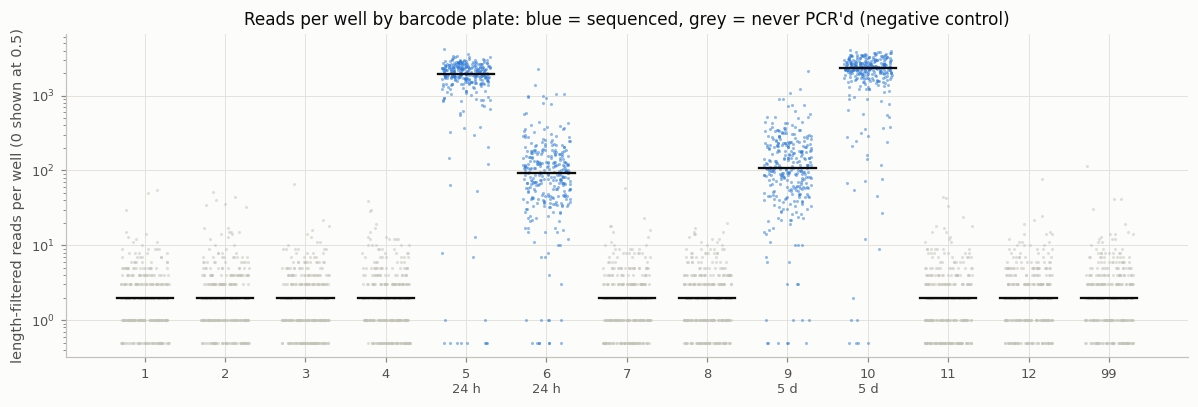

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
order = sorted(st.plate.unique())
for k, p in enumerate(order):
    v = st[st.plate == p].reads_len_ok.clip(lower=0.5)
    col = P.CAT[0] if p in SEQ else P.AXIS
    ax.scatter(k + np.random.default_rng(p).uniform(-.3, .3, len(v)), v, s=4, color=col, alpha=.5, lw=0)
    ax.plot([k - .35, k + .35], [v.median()] * 2, color=P.INK, lw=1.5)
ax.set(yscale="log", xticks=range(len(order)), ylabel="length-filtered reads per well (0 shown at 0.5)",
       title="Reads per well by barcode plate: blue = sequenced, grey = never PCR'd (negative control)")
ax.set_xticklabels([f"{p}" + (f"\n{TP[p].split(' · ')[1]}" if p in SEQ else "") for p in order])
fig.tight_layout(); savefig(fig, "01_depth_by_plate.png")

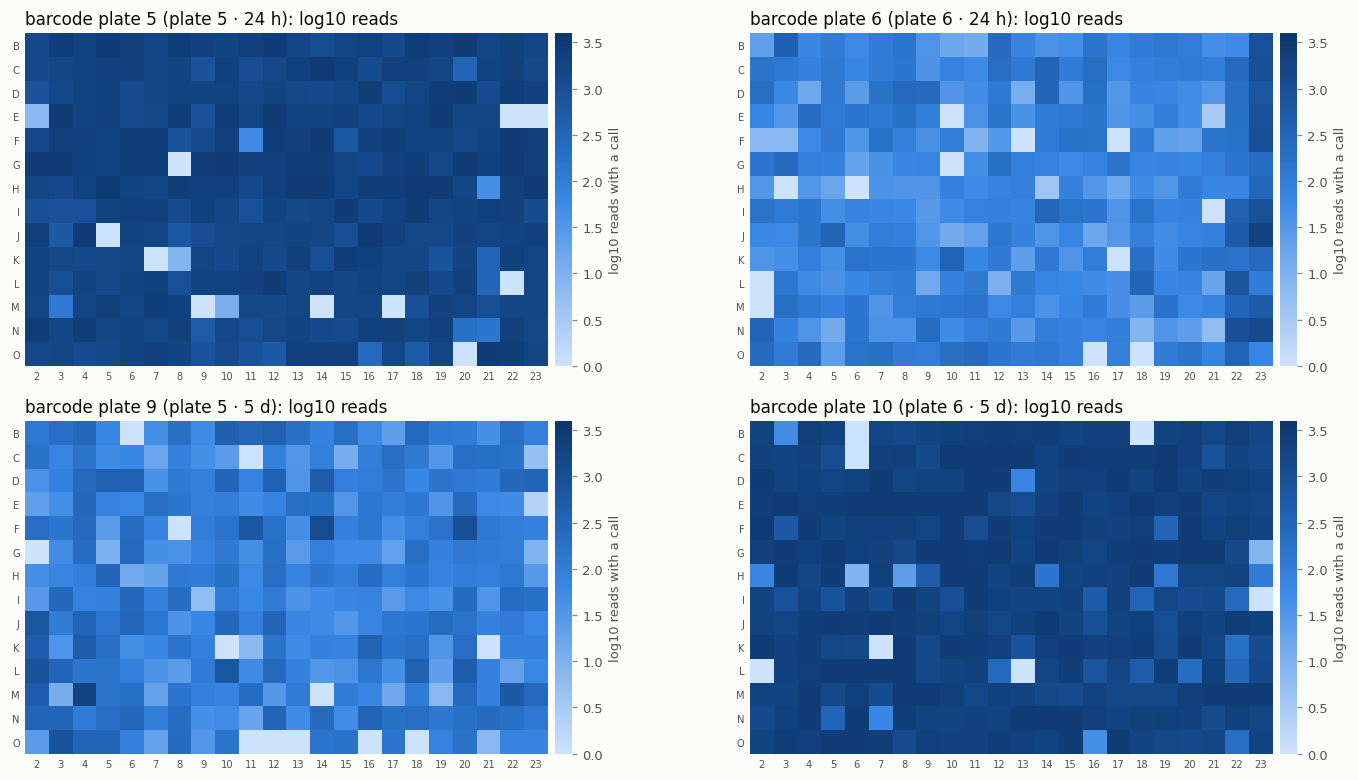

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(14, 7.2))
for ax, p in zip(axs.flat, SEQ):
    g = ws[ws.plate == p]
    P.plate_map(ax, np.log10(g.reads_called.clip(lower=1)), g.well, vmin=0, vmax=3.6,
                title=f"barcode plate {p} ({TP[p]}): log10 reads", label="log10 reads with a call")
fig.tight_layout(); savefig(fig, "01_depth_maps.png")

Plates **6 and 9 are ~20× shallower** than 5 and 10 (median ~85–95 called reads vs
~1800–2100), uniformly across the plate rather than in a block, which is what a weak
PCR on the whole plate looks like. Section 5 shows these two plates also share a
contaminating DNA profile, a second reason to re-run their PCR.

## 2. How reads are called — and what fraction is what

A genuine read's distance to its own reference is set by its error rate. On the deep
plates, reads of each well's dominant member sit a median distance equal to their
expected error count E = length × 10^(−q/10) (q 16–18: 28 bp vs E 28; q 22–24: 10 vs 7).
Beyond that there is a tail of reads ≥ 40 bp from every reference at *every* quality,
made of chimeras and sequence the DB doesn't hold. A pooled histogram has no valley
between the two, so the cut is per read: **near if d ≤ 12 + 2E**, and reads with q < 16
(E ≈ 45–110 bp, which overlaps the chimera tail) get no call.

In [5]:
cal = pd.read_csv(OUT / "q02_call_calibration.csv")
cal.round(3)

,qbin,reads,median_d,median_E,p90_d,share_beyond_cut,share_of_all_reads
0,"(0, 14]",46185,86.0,88.879,131.0,0.016,0.057
1,"(14, 16]",33811,44.0,45.012,71.0,0.048,0.042
2,"(16, 18]",51431,28.0,28.298,52.0,0.073,0.064
3,"(18, 20]",85157,18.0,17.864,40.0,0.087,0.107
4,"(20, 22]",123344,13.0,11.437,34.0,0.098,0.154
5,"(22, 24]",136757,10.0,7.308,30.0,0.108,0.169
6,"(24, 26]",126524,8.0,4.670,27.0,0.116,0.154
7,"(26, 45]",213899,6.0,2.135,23.0,0.126,0.253


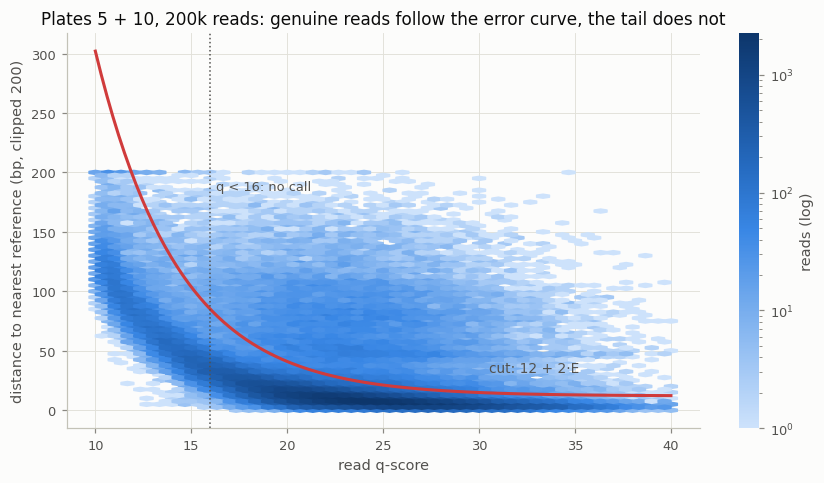

In [6]:
reads = pd.read_parquet(OUT / "q01_read_assignments.parquet", columns=["sample_id", "length", "q", "d_member", "d_other"])
deep = reads[reads.sample_id.astype(str).str.startswith(("Plate05", "Plate10"))].sample(200000, random_state=0)
deep["d_best"] = np.fmin(deep.d_member, deep.d_other)
fig, ax = plt.subplots(figsize=(8, 4.5))
h = ax.hexbin(deep.q.clip(10, 40), deep.d_best.clip(0, 200), gridsize=(45, 40), bins="log", cmap=P.SEQ, mincnt=1)
qq = np.linspace(10, 40, 100)
ax.plot(qq, 12 + 2 * 1450 * 10 ** (-qq / 10), color=P.STATUS["critical"], lw=2)
ax.text(30.5, 32, "cut: 12 + 2·E", color=P.INK2, fontsize=9)
ax.axvline(16, color=P.INK2, lw=1, ls=":"); ax.text(16.3, 185, "q < 16: no call", color=P.INK2, fontsize=8.5)
ax.set(xlabel="read q-score", ylabel="distance to nearest reference (bp, clipped 200)",
       title="Plates 5 + 10, 200k reads: genuine reads follow the error curve, the tail does not")
plt.colorbar(h, ax=ax, label="reads (log)").outline.set_visible(False)
fig.tight_layout(); savefig(fig, "01_read_call.png")

,member_frac,foreign_frac,unexplained_frac,unexplained_chimera_frac,low_quality_frac
plate,,,,,
5,0.810,0.017,0.163,0.077,0.099
6,0.479,0.315,0.180,0.068,0.102
9,0.548,0.274,0.144,0.054,0.103
10,0.842,0.024,0.115,0.041,0.098


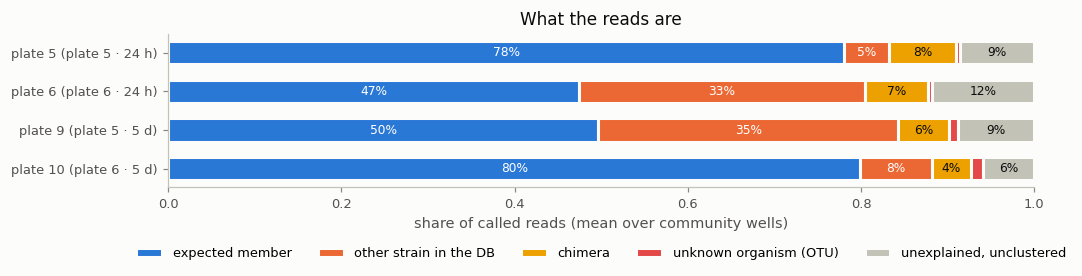

In [7]:
cols = ["member_frac", "foreign_frac", "unexplained_chimera_frac", "unexplained_unknown_otu_frac", "unexplained_unclustered_frac"]
names = ["expected member", "other strain in the DB", "chimera", "unknown organism (OTU)", "unexplained, unclustered"]
w = ws[ws.well_type == "community"]
share = w.groupby("plate")[cols].mean()
share = share.div(share.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(len(share))
colors = [P.CAT[0], P.CAT[1], P.CAT[3], P.CAT[7], "#c3c2b7"]
for c, n, col in zip(cols, names, colors):
    ax.barh(range(len(share)), share[c], left=left, color=col, height=.6, label=n, edgecolor=P.SURFACE, lw=2)
    for i, v in enumerate(share[c]):
        if v > .04:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="#0b0b0b" if col in (P.CAT[3], "#c3c2b7") else "white")
    left += share[c].to_numpy()
ax.set_yticks(range(len(share)), [f"plate {p} ({TP[p]})" for p in share.index]); ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="share of called reads (mean over community wells)", title="What the reads are")
ax.grid(False); ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(.5, -.55))
fig.tight_layout(); savefig(fig, "01_read_classes.png")
w.groupby("plate")[["member_frac", "foreign_frac", "unexplained_frac", "unexplained_chimera_frac", "low_quality_frac"]].median().round(3)

## 3. Demultiplexing cross-talk, measured on the never-PCR'd plates

**The run used `-e 6`** (see section 1). Two consequences, both measured here:

1. Most reads landing in never-PCR'd wells are a **~1260 bp off-target product** whose
   second barcode matched at edit distance exactly 6 with no primer found (minibar tag
   `h-(6,-1)`). The 1300–1600 bp read filter removes them before any analysis, which is
   why the counts below use length-filtered reads.
2. What remains is genuine 16S that was mis-assigned. A misread barcode end sends a read
   to a well **sharing the other barcode**, so each well's expected stray reads are fitted
   as `a·F + b·R + c` (F, R = reads in sequenced wells sharing its forward / reverse
   barcode), on the 2772 never-PCR'd wells.

never-PCR'd wells: 19,189 reads as demultiplexed -> 8,589 after the length filter (0.63% of length-filtered reads)
rates: a = 4.1e-05 (forward barcode shared), b = 1.6e-04 (reverse shared) per read of a sharing well; overdispersion 8.3
mechanism check: 99.2% of stray reads carry a strain found in a barcode-sharing well, vs 94.2% if sharing partners were random (95th pct 95.2%)
most reads any ONE strain reached in a never-PCR'd well: 99th pct 7, max 47


,50%,90%,max
plate,,,
5,0.15,0.31,81.38
6,3.32,11.22,249.14
9,2.72,9.65,327.91
10,0.13,0.32,153.74


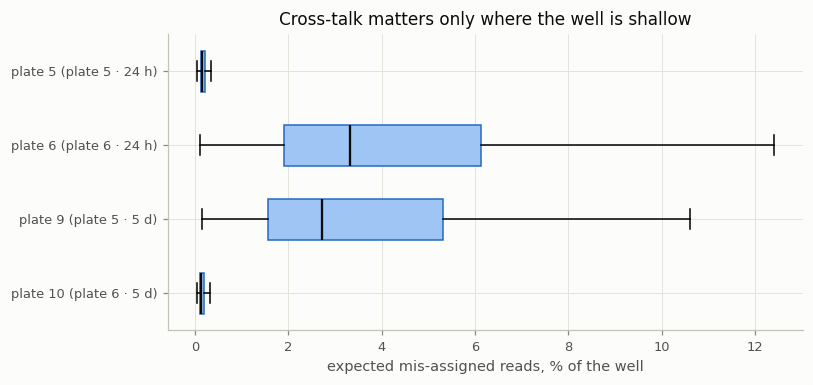

In [8]:
xf = pd.read_csv(OUT / "q02_crosstalk_fit.csv").iloc[0]
xw = pd.read_csv(OUT / "q02_crosstalk_wells.csv")
print(f"never-PCR'd wells: {xf.stray_reads_unsequenced_unfiltered:,.0f} reads as demultiplexed -> "
      f"{xf.stray_reads_unsequenced:,.0f} after the length filter "
      f"({xf.stray_reads_unsequenced / (xf.stray_reads_unsequenced + xf.reads_sequenced):.2%} of length-filtered reads)")
print(f"rates: a = {xf.a_fwd_share:.1e} (forward barcode shared), b = {xf.b_rev_share:.1e} (reverse shared) "
      f"per read of a sharing well; overdispersion {xf.dispersion:.1f}")
print(f"mechanism check: {xf.validation_explained:.1%} of stray reads carry a strain found in a barcode-sharing "
      f"well, vs {xf.validation_null_mean:.1%} if sharing partners were random (95th pct {xf.validation_null_p95:.1%})")
print(f"most reads any ONE strain reached in a never-PCR'd well: 99th pct {xf.strain_ceiling_p99:.0f}, "
      f"max {xf.strain_ceiling_max:.0f}")
s = xw[xw.sequenced]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
data = [s[s.plate == p].expected_stray_frac.dropna() * 100 for p in SEQ]
bp = ax.boxplot(data, vert=False, widths=.55, patch_artist=True, showfliers=False, medianprops=dict(color=P.INK, lw=1.5))
for b in bp["boxes"]:
    b.set(facecolor=P.SEQ_STEPS[1], edgecolor=P.SEQ_STEPS[4])
ax.set_yticks(range(1, 5), [f"plate {p} ({TP[p]})" for p in SEQ]); ax.invert_yaxis()
ax.set(xlabel="expected mis-assigned reads, % of the well", title="Cross-talk matters only where the well is shallow")
fig.tight_layout(); savefig(fig, "01_crosstalk.png")
s.groupby("plate").expected_stray_frac.describe(percentiles=[.5, .9])[["50%", "90%", "max"]].mul(100).round(2)

On the deep plates cross-talk is ~0.15% of a well. On plates 6 and 9 it is a few
percent (10% at the 90th percentile), so a foreign strain there is only called if
it has ≥ 3 reads, ≥ 1% of the well, **and ≥ 3× the reads cross-talk would put there**
(`q04_foreign.csv`, column `called`). Re-demultiplexing at `-e 4` would cut this
roughly 4× (20260907 calibration: 1.2% vs 5.2% false assignment).

## 4. Did the intended strains land?

### 4a. Identity at base resolution
Nearest-reference assignment cannot tell a strain from a relative a few bp away. So for
every (well, strain) read group with ≥ 10 reads, a spoa consensus is built from its
best reads and compared base-exactly with the reference.

3,363 member read groups (well x strain, >= 10 reads): 97.7% identical to the reference, 99.5% within 2 bp (het-site wobble), 18 further
further than 2 bp, by strain: {'A18': {'size': 1, 'max': 3}, 'A24': {'size': 1, 'max': 16}, 'K16': {'size': 7, 'max': 4}, 'K17': {'size': 1, 'max': 4}, 'O10': {'size': 7, 'max': 7}, 'P23': {'size': 1, 'max': 4}}


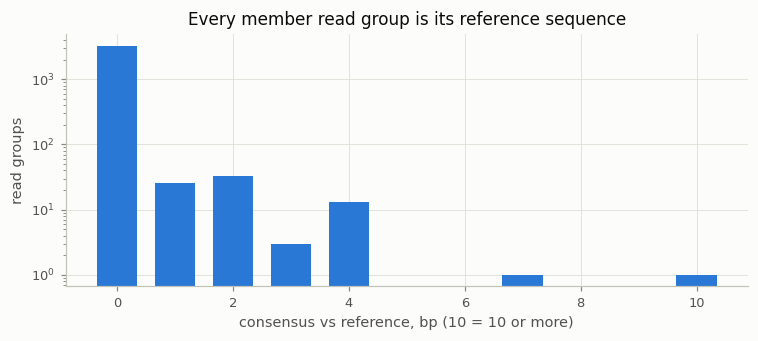

In [9]:
grp = pd.read_csv(OUT / "q03_group_consensus.csv")
m = grp[grp.call == "member"]
print(f"{len(m):,} member read groups (well x strain, >= 10 reads): "
      f"{(m.bp_to_ref == 0).mean():.1%} identical to the reference, {(m.bp_to_ref <= 2).mean():.1%} within 2 bp "
      f"(het-site wobble), {(m.bp_to_ref > 2).sum()} further")
print("further than 2 bp, by strain:", m[m.bp_to_ref > 2].groupby("strain").bp_to_ref.agg(["size", "max"]).to_dict("index"))
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = m.bp_to_ref.clip(upper=10).value_counts().sort_index()
ax.bar(vals.index, vals.values, color=P.CAT[0], width=.7)
ax.set(yscale="log", xlabel="consensus vs reference, bp (10 = 10 or more)", ylabel="read groups",
       title="Every member read group is its reference sequence")
fig.tight_layout(); savefig(fig, "01_identity.png")

### 4b. Is every strain detected where it was put?

Per (well, expected member): **present** ≥ 1% of called reads, **trace** 1+ reads below
that, **absent** none. An absence is informative only if the well is deep enough that a
1% member would have shown up (rule of three: 3/n < 1%, i.e. > 300 reads), which on
plates 6 and 9 it almost never is.

In [10]:
t = mt.groupby("plate").status.value_counts(normalize=True).unstack().reindex(columns=["present", "trace", "absent", "no_data"]).fillna(0)
t["absent, informative"] = mt.assign(x=(mt.status == "absent") & mt.absence_informative).groupby("plate").x.mean()
t.index = [f"{p} ({TP[p]})" for p in t.index]
(t * 100).round(1)

status,present,trace,absent,no_data,"absent, informative"
5 (plate 5 · 24 h),51.3,26.0,20.2,2.5,15.5
6 (plate 6 · 24 h),39.4,5.3,51.2,4.0,1.8
9 (plate 5 · 5 d),30.3,5.3,62.5,1.8,4.8
10 (plate 6 · 5 d),38.1,21.3,39.4,1.2,36.2


,5,6,9,10,source_od,tier
strain,,,,,,
K11,0.000,0.000,0.020,0.000,0.136,A
I8,0.067,0.000,0.000,0.000,0.139,A
B17,0.154,0.091,0.000,0.121,2.666,A
G9,0.238,0.000,0.000,0.000,0.593,B
A3,0.282,0.056,0.000,0.000,1.595,A
K6,0.381,0.026,0.119,0.026,0.354,B
P21,0.392,0.056,0.039,0.028,0.354,B
H5,0.436,0.051,0.128,0.333,1.659,B
D16,0.436,0.071,0.077,0.476,0.750,A


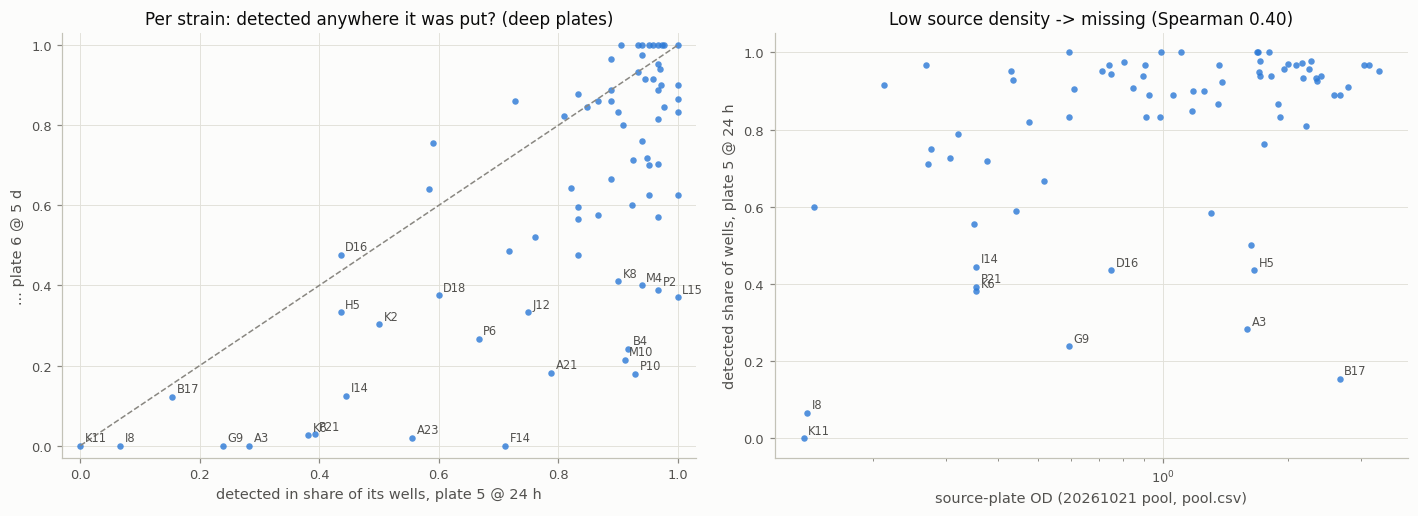

In [11]:
sd = pd.read_csv(OUT / "q04_strain_detection.csv")
det = mt.assign(det=mt.reads > 0).groupby(["strain", "plate"]).det.mean().unstack()
pool = pd.read_csv(config.POOL_CSV).set_index("strain")
det = det.join(pool[["source_od", "tier"]])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(det[5], det[10], s=18, color=P.CAT[0], alpha=.8, lw=0)
for s_, r in det[(det[5] < .45) | (det[10] < .45)].iterrows():
    ax[0].annotate(s_, (r[5], r[10]), xytext=(3, 3), textcoords="offset points", fontsize=7.5, color=P.INK2)
ax[0].plot([0, 1], [0, 1], color=P.MUTED, ls="--", lw=1)
ax[0].set(xlabel="detected in share of its wells, plate 5 @ 24 h", ylabel="... plate 6 @ 5 d",
          title="Per strain: detected anywhere it was put? (deep plates)", xlim=(-.03, 1.03), ylim=(-.03, 1.03))
ax[1].scatter(det.source_od, det[5], s=18, color=P.CAT[0], alpha=.8, lw=0)
for s_, r in det[det[5] < .45].iterrows():
    ax[1].annotate(s_, (r.source_od, r[5]), xytext=(3, 3), textcoords="offset points", fontsize=7.5, color=P.INK2)
ax[1].set(xscale="log", xlabel="source-plate OD (20261021 pool, pool.csv)", ylabel="detected share of wells, plate 5 @ 24 h",
          title=f"Low source density -> missing (Spearman {det[['source_od', 5]].corr('spearman').iat[0, 1]:.2f})")
fig.tight_layout(); savefig(fig, "01_strain_detection.png")
det.sort_values(5).head(12).round(3)

In [12]:
m5 = mt[mt.plate == 5]
rp = m5.groupby(["community_id", "strain"]).agg(n=("reads", "size"), det=("reads", lambda x: int((x > 0).sum())),
                                                pres=("status", lambda x: int((x == "present").sum())))
rp = rp[rp.n == 3]
fails = {"K11", "I8", "B17"}
rp2 = rp[~rp.index.get_level_values("strain").isin(fails)]
out = pd.DataFrame({"detected (>=1 read)": rp2.det.value_counts().sort_index(),
                    "present (>=1%)": rp2.pres.value_counts().sort_index()})
out.index = [f"in {i} of 3 replicates" for i in out.index]
print(f"plate 5 @ 24 h, (community, member) cells with all 3 replicates, excluding K11 / I8 / B17: {len(rp2)}")
out

plate 5 @ 24 h, (community, member) cells with all 3 replicates, excluding K11 / I8 / B17: 811


,detected (>=1 read),present (>=1%)
in 0 of 3 replicates,67,303
in 1 of 3 replicates,50,52
in 2 of 3 replicates,155,102
in 3 of 3 replicates,539,354


## 5. What else is in the wells?

A foreign read is classified by **where it could have come from**:

| source class | meaning |
|---|---|
| `tracks_member` | the foreign sequence appears almost only in wells holding one particular member → that member's **source well** holds it too |
| `same_culture_plate` | the strain is a member elsewhere on the same culture plate → cross-well transfer possible |
| `other_culture_plate` | the strain is only used on other plates of this experiment (1–4, or the other passage plate) |
| `not_in_experiment` | never inoculated anywhere in this experiment → it entered from outside the cultures |
| `unknown_otu` | a non-chimeric sequence the reference doesn't hold, not tied to a member |

source_class,tracks_member,same_culture_plate,other_culture_plate,not_in_experiment,unknown_otu,community wells
plate,,,,,,
5,81,8,2,9,8,306
6,38,41,88,184,3,306
9,51,58,86,194,0,306
10,84,62,20,54,13,306


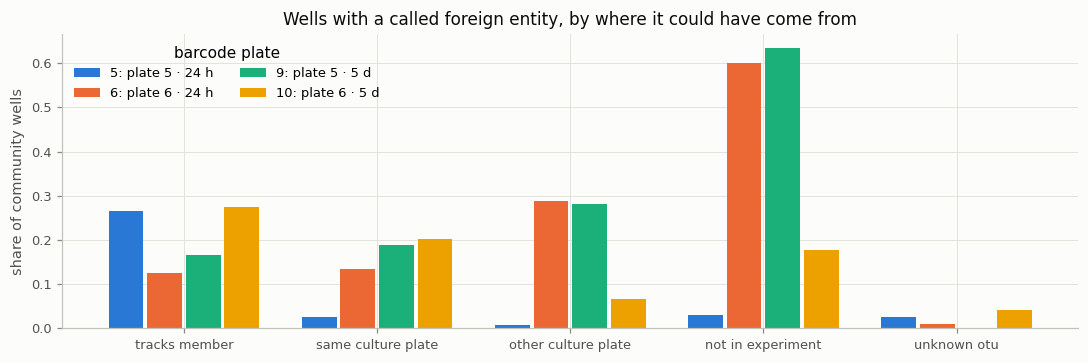

In [13]:
called = fo[fo.called]
cls_order = ["tracks_member", "same_culture_plate", "other_culture_plate", "not_in_experiment", "unknown_otu"]
ev = called.groupby(["plate", "source_class"]).size().unstack(fill_value=0).reindex(columns=cls_order, fill_value=0)
wells_any = called.groupby(["plate", "source_class"]).sample_id.nunique().unstack(fill_value=0).reindex(columns=cls_order, fill_value=0)
nw = ws[ws.well_type == "community"].groupby("plate").size()
fig, ax = plt.subplots(figsize=(10, 3.4))
frac = wells_any.div(nw, axis=0)
x = np.arange(len(cls_order)); wdt = .2
for k, p in enumerate(SEQ):
    ax.bar(x + (k - 1.5) * wdt, frac.loc[p], width=wdt - .02, color=P.CAT[k], label=f"{p}: {TP[p]}")
ax.set_xticks(x, [c.replace("_", " ") for c in cls_order])
ax.set(ylabel="share of community wells", title="Wells with a called foreign entity, by where it could have come from")
ax.legend(title="barcode plate", ncol=2)
fig.tight_layout(); savefig(fig, "01_foreign_sources.png")
wells_any.assign(**{"community wells": nw})

### 5a. External DNA on the weak plates

The strains behind most foreign calls on plates 6 and 9 (A13, A10, A16, L6, M12, …)
**were never inoculated in this experiment**, so neither the cultures nor demultiplexing
can have put them there. Two observations place their source at the PCR:

median external reads per well: {5: 6.0, 6: 14.5, 9: 14.0, 10: 6.5} 
median share of called reads: {5: 0.004, 6: 0.191, 9: 0.156, 10: 0.003}
plate 6 vs 9 external profile: Spearman 0.87; plate 5 vs 10: 0.68; plate 6 vs 10: 0.45


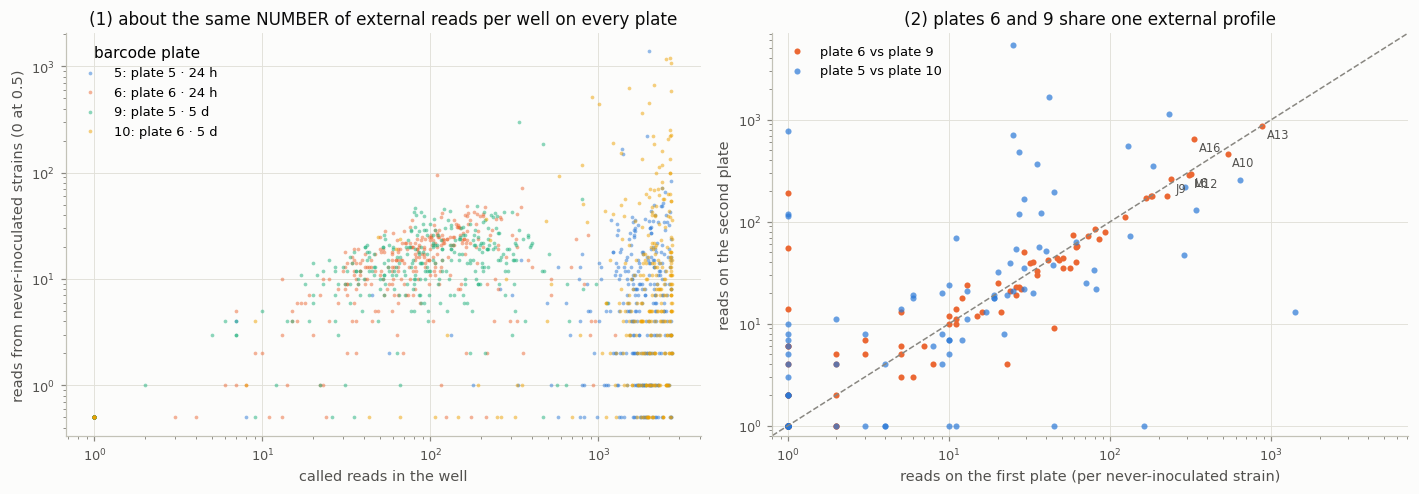

In [14]:
lay_all = cio.load_layout(config.LAYOUT_CSV)
used = set(m for ms in lay_all.members_list for m in ms)
ext = fo[(fo.kind == "strain") & ~fo.entity.isin(used) & ~fo.twin_of_member]
per = ext.groupby("sample_id").reads.sum()
w = ws[ws.well_type == "community"].assign(ext=lambda t: t.sample_id.map(per).fillna(0))
prof = ext.groupby(["entity", "plate"]).reads.sum().unstack(fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for k, p in enumerate(SEQ):
    g = w[w.plate == p]
    ax[0].scatter(g.reads_called.clip(lower=1), g.ext.clip(lower=.5), s=6, alpha=.5, color=P.CAT[k], lw=0, label=f"{p}: {TP[p]}")
ax[0].set(xscale="log", yscale="log", xlabel="called reads in the well", ylabel="reads from never-inoculated strains (0 at 0.5)",
          title="(1) about the same NUMBER of external reads per well on every plate")
ax[0].legend(title="barcode plate")
lim = [.8, prof.max().max() * 1.3]
ax[1].scatter(prof[6].clip(lower=1), prof[9].clip(lower=1), s=16, color=P.CAT[1], lw=0, label="plate 6 vs plate 9")
ax[1].scatter(prof[5].clip(lower=1), prof[10].clip(lower=1), s=16, color=P.CAT[0], lw=0, alpha=.7, label="plate 5 vs plate 10")
ax[1].plot(lim, lim, color=P.MUTED, ls="--", lw=1)
for e in prof.sort_values(6, ascending=False).index[:6]:
    ax[1].annotate(e, (prof.at[e, 6], prof.at[e, 9]), xytext=(3, -8), textcoords="offset points", fontsize=7.5, color=P.INK2)
ax[1].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="reads on the first plate (per never-inoculated strain)",
          ylabel="reads on the second plate", title="(2) plates 6 and 9 share one external profile")
ax[1].legend()
fig.tight_layout(); savefig(fig, "01_external_dna.png")
print("median external reads per well:", w.groupby("plate").ext.median().to_dict(),
      "\nmedian share of called reads:", (w.ext / w.reads_called).groupby(w.plate).median().round(3).to_dict())
print(f"plate 6 vs 9 external profile: Spearman {prof[[6, 9]].corr('spearman').iat[0, 1]:.2f}; "
      f"plate 5 vs 10: {prof[[5, 10]].corr('spearman').iat[0, 1]:.2f}; plate 6 vs 10: {prof[[6, 10]].corr('spearman').iat[0, 1]:.2f}")

(1) Each well carries roughly the same *number* of external reads (~10–15) wherever it
is; in a deep well that is < 1%, in a shallow one ~20%. That is a fixed amount of foreign
template competing with a small amount of real template, i.e. **low-input PCR picking
up contaminating 16S DNA**, not something growing in the culture.
(2) Plates 6 and 9 hold *different* cultures (plate 6 at 24 h, plate 5 at 5 d), yet their
external profiles match strain for strain, and differ from plates 5 and 10. Whatever
those two plates were amplified with (master mix, water, primer plate, or their position
in the PCR run) carried the same contaminating DNA, and it is the same pair whose PCR
was weak. A13, A10, … are in the 384 collection, so carryover of amplicon or gDNA from
earlier full-collection runs is the likely source.
**For the re-run of plates 6 and 9: fresh reagents and a no-template control.**

### 5b. Source wells holding a second organism

A foreign sequence that turns up almost exclusively in wells containing one particular
member is not cross-contamination; it was **inoculated with that member** from its
source well. Fisher test of every recurrent foreign entity against every member
(Bonferroni over members), at 24 h and 5 d separately:

In [15]:
assoc = pd.read_csv(OUT / "q04_foreign_association.csv")
tr = assoc[assoc.verdict.str.startswith("tracks")].sort_values(["best_member", "timepoint"])
tr[["entity", "kind", "timepoint", "best_member", "wells", "with_member", "member_wells", "coverage", "specificity", "p_bonferroni"]].round(3)

,entity,kind,timepoint,best_member,wells,with_member,member_wells,coverage,specificity,p_bonferroni
22,B3,strain,24h,A21,10,10,66,0.152,1.000,0.000
100,O7,strain,24h,A24,9,8,57,0.140,0.889,0.000
69,I15,strain,24h,B4,4,4,57,0.070,1.000,0.005
54,F2,strain,5d,F14,19,18,84,0.214,0.947,0.000
55,F7,strain,24h,F17,57,54,72,0.750,0.947,0.000
56,F7,strain,5d,F17,40,37,72,0.514,0.925,0.000
82,K3,strain,24h,F2,6,6,69,0.087,1.000,0.000
65,H14,strain,5d,G2,6,6,72,0.083,1.000,0.000
67,H8,strain,5d,G2,11,11,72,0.153,1.000,0.000
113,U108,unknown_otu,5d,G2,5,5,72,0.069,1.000,0.001


In [16]:
otus = pd.read_csv(OUT / "q03_otus.csv")
print(f"{len(otus)} unexplained-read OTUs; {int(otus.chimera.sum())} are two-parent chimeras "
      "(recurrent ones are the same member pairs recombining in many wells)")
otus[~otus.chimera].sort_values("n_wells", ascending=False).head(10)[["otu", "n_wells", "n_reads", "nearest", "nearest_bp", "split_bp", "parent_a", "parent_b"]]

905 unexplained-read OTUs; 837 are two-parent chimeras (recurrent ones are the same member pairs recombining in many wells)


,otu,n_wells,n_reads,nearest,nearest_bp,split_bp,parent_a,parent_b
0,U001,49,5541,G17,43.0,38.0,A13,B4
11,U012,11,376,A10,3.0,2.0,A10,A10
2,U003,8,692,G2,1.0,12.0,G2,G2
141,U142,7,207,A10,4.0,4.0,A10,A10
172,U173,6,185,G6,11.0,11.0,B2,G6
47,U048,6,189,O17,0.5,0.5,A13,O17
32,U033,3,195,O6,2.0,2.0,O6,O6
321,U322,3,90,I1,0.0,0.0,B19,I1
174,U175,2,61,B19,3.0,3.0,B19,B19
7,U008,1,159,N23,22.0,9.0,B19,I4


**U001** is a real organism, not a chimera (no two-parent split explains it): 43 bp
from the nearest reference (G17), in ~60 wells, and **every one of those wells contains
M19**. E14 tracks M19 the same way. So M19's source well holds at least two other
organisms besides M19's own 16S (which is also present: M19's read groups match its
reference exactly). Likewise F17's well carries F7, F14's carries F2 and G2's carries H8.
These came in with the inoculum, so they are part of what "M19" means in this
experiment, and analyses should either treat them as part of that member or flag
every M19 / F17 / F14 / G2 community.

### 5c. Contamination during passaging (5 d)

If wells contaminate each other during daily dilution, a foreign strain at 5 d should
sit in a **neighbouring** well's community more often than chance. The test only uses
events whose strain is on that culture plate, keeps each event's strain, and places it
at random positions for the null. **The 24 h plates are the control**: there has been no
passaging yet, so they should show no enrichment.

,plate,timepoint,culture_plate,events,share_in_neighbour,null_mean,null_p95,enrichment,p
0,5,24h,5,9,0.556,0.544,0.778,1.021,0.604
1,6,24h,6,49,0.510,0.515,0.633,0.991,0.596
2,9,5d,5,76,0.671,0.509,0.592,1.319,0.002
3,10,5d,6,77,0.727,0.493,0.584,1.475,0.001


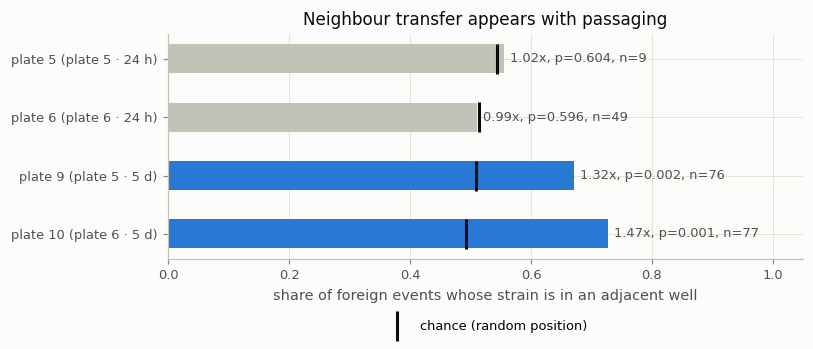

In [17]:
nt = pd.read_csv(OUT / "q04_neighbour_test.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(nt))
ax.barh(y, nt.share_in_neighbour, height=.5, color=[P.CAT[0] if t == "5d" else P.AXIS for t in nt.timepoint])
ax.scatter(nt.null_mean, y, marker="|", s=400, color=P.INK, zorder=3, label="chance (random position)")
for i, r in nt.iterrows():
    ax.text(r.share_in_neighbour + .01, i, f"{r.enrichment:.2f}x, p={r.p:.3f}, n={r.events}", va="center", fontsize=8.5, color=P.INK2)
ax.set_yticks(y, [f"plate {r.plate} ({TP[r.plate]})" for r in nt.itertuples()]); ax.invert_yaxis()
ax.set(xlim=(0, 1.05), xlabel="share of foreign events whose strain is in an adjacent well",
       title="Neighbour transfer appears with passaging")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.22), ncol=1)
fig.tight_layout(); savefig(fig, "01_neighbour_test.png")
nt.round(3)

**Who is spreading?** Plate 6 at 5 d (barcode plate 10) is the deep 5 d plate, so it is
where invaders can be counted. For each foreign entity: in how many wells it is called
at 5 d, and how far it had got at 24 h. The 24 h comparison uses plate 5 (deep), because
plate 6's own 24 h sample is too shallow to show a trace.

In [18]:
inv = (called[called.plate == 10].groupby(["entity", "source_class"])
       .agg(wells_5d=("sample_id", "nunique"), reads_5d=("reads", "sum"), median_share_5d=("frac", "median"))
       .reset_index().sort_values("wells_5d", ascending=False))
p5 = fo[fo.plate == 5].groupby("entity").agg(wells_with_reads_24h=("sample_id", "nunique"), reads_24h=("reads", "sum"))
inv = inv.join(p5, on="entity").fillna({"wells_with_reads_24h": 0, "reads_24h": 0})
pool_members = {m for ms in lay_all[lay_all.culture_plate == 6].members_list for m in ms}
inv["member_of_plate_6_communities"] = inv.entity.isin(pool_members)
inv.head(15).round(3)

,entity,source_class,wells_5d,reads_5d,median_share_5d,wells_with_reads_24h,reads_24h,member_of_plate_6_communities
29,G4,same_culture_plate,30,3863,0.041,16.0,26.0,True
19,E16,not_in_experiment,26,5344,0.032,13.0,25.0,False
58,U001,tracks_member,26,6434,0.100,29.0,1126.0,False
26,F7,tracks_member,24,2855,0.049,53.0,2405.0,False
23,F2,tracks_member,11,3086,0.079,19.0,180.0,True
48,O17,same_culture_plate,10,1334,0.022,35.0,67.0,True
17,E14,tracks_member,10,495,0.020,29.0,781.0,False
34,H8,tracks_member,9,1079,0.019,18.0,233.0,False
30,G6,not_in_experiment,6,1614,0.095,48.0,8878.0,False
39,J5,same_culture_plate,6,214,0.070,23.0,43.0,True


- **G4** is a member of some plate-6 communities and at 5 d turns up as an *intruder* in
  ~30 other wells (up to 30% of a well). At 24 h it is only a trace anywhere. A strong
  competitor spreading between wells during passaging.
- **A1 / A4 / A6** are one 16S identity (0 bp apart) inoculated only on the main plates
  1–4, yet called in plate-6 wells at 5 d. That is transfer **between plates**, which
  fits all six plates being diluted side by side every day.
- The plate-6 blank J11 at 5 d (2,250 reads) is exactly these: G4 + A1/A4/A6.

In [19]:
d5 = called[(called.timepoint == "5d") & called.source_class.isin(["same_culture_plate", "other_culture_plate", "unknown_otu"])]
deep24 = d5[d5.culture_plate == 5]          # culture plate 5: 24 h side deep -> 'absent at 24 h' is meaningful
print(f"culture plate 5, cross-well / cross-plate / unknown foreign events at 5 d: {len(deep24)}; "
      f"absent from the same well at 24 h (~{deep24.depth_same_well_24h.median():.0f} reads deep): "
      f"{(deep24.reads_same_well_24h == 0).mean():.0%}  -> they arrived during passaging")

culture plate 5, cross-well / cross-plate / unknown foreign events at 5 d: 174; absent from the same well at 24 h (~1960 reads deep): 87%  -> they arrived during passaging


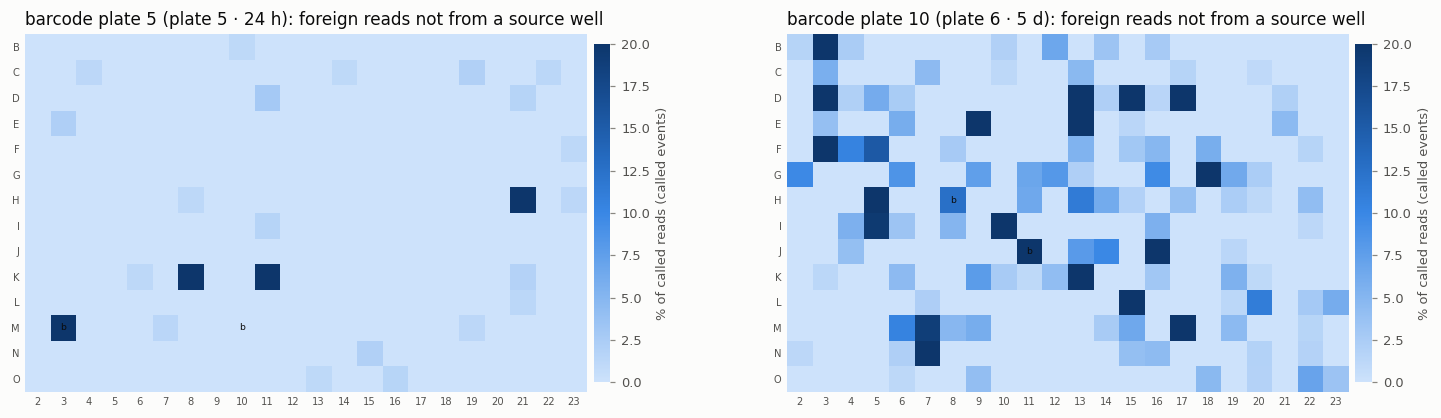

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
for ax, p in zip(axs, (5, 10)):
    g = fl[fl.plate == p]
    v = (g.foreign_same_culture_plate + g.foreign_other_culture_plate + g.foreign_not_in_experiment + g.foreign_unknown_otu) * 100
    P.plate_map(ax, v, g.well, vmin=0, vmax=20, title=f"barcode plate {p} ({TP[p]}): foreign reads not from a source well",
                label="% of called reads (called events)",
                annotate={w_: "b" for w_ in g.well[g.well_type == "blank"]})
fig.tight_layout(); savefig(fig, "01_foreign_maps.png")

### 5d. Blank (medium-only) wells: reads and OD

In [21]:
bl = ws[ws.well_type == "blank"][["sample_id", "plate", "well", "reads_called", "member", "foreign", "unexplained"]]
top = (fo[fo.sample_id.isin(bl.sample_id)].sort_values("reads", ascending=False)
       .groupby("sample_id").apply(lambda g: ", ".join(f"{e} {r}" for e, r in zip(g.entity.head(4), g.reads.head(4))), include_groups=False))
bl["top foreign (reads)"] = bl.sample_id.map(top)
bl["timepoint"] = bl.plate.map(TP)
bl

,sample_id,plate,well,reads_called,member,foreign,unexplained,top foreign (reads),timepoint
243,Plate05_M3,5,M3,115.0,0.0,110.0,5.0,"K11 26, M16 11, L11 8, I11 6",plate 5 · 24 h
250,Plate05_M10,5,M10,11.0,0.0,9.0,2.0,"J18 2, M10 1, C21 1, L11 1",plate 5 · 24 h
446,Plate06_H8,6,H8,34.0,0.0,24.0,10.0,"A22 3, A10 3, A16 2, A13 2",plate 6 · 24 h
493,Plate06_J11,6,J11,20.0,0.0,15.0,5.0,"A13 3, G17 3, A10 3, A16 1",plate 6 · 24 h
859,Plate09_M3,9,M3,12.0,0.0,6.0,6.0,"C21 2, J18 2, J16 1, A10 1",plate 5 · 5 d
866,Plate09_M10,9,M10,74.0,0.0,65.0,9.0,"A6 23, A4 14, A1 5, A16 3",plate 5 · 5 d
1062,Plate10_H8,10,H8,24.0,0.0,23.0,1.0,"B3 4, J5 3, F7 2, A22 1",plate 6 · 5 d
1109,Plate10_J11,10,J11,2247.0,0.0,1968.0,279.0,"G4 701, A4 511, A6 508, A1 103",plate 6 · 5 d


day                   1     2     3     4     5     6     7     8     9     10    11
culture_plate well                                                                  
1             F16   0.05  0.03  0.16  0.22  0.18  0.21  0.26  0.23  1.00  0.26  0.20
              F20   0.05  0.04  0.04  0.03  0.04  0.04  0.03  0.05  0.16  0.04  0.17
2             G5    0.05  0.03  0.03  0.03  0.03  0.03  0.03  0.03  0.03  0.12  0.20
              I22   0.04  0.03  0.04  0.17  0.07  0.12  0.15  0.18  0.19  0.14  0.18
3             F20   0.05  0.04  0.05  0.04  0.04  0.04  0.04  0.04  0.04  0.03  0.03
              O19   0.04  0.04  0.04  0.03  0.03  0.04  0.04  0.19  0.12  0.09  0.16
4             I3    0.04  0.03  0.03  0.03  0.04  0.04  0.03  0.21  0.18  0.14  0.20
              K2    0.05  0.04  0.03  0.03  0.04  0.04  0.04  0.04  0.04  0.03  0.27
5             M10   0.04  0.03  0.05  0.03  0.03  0.05  0.12  0.12  0.15  0.11  0.17
              M3    0.04  0.03  0.04  0.03  0.03  0.03  0.04  0.03  0.05  0.29  0.21
6             H8    0.05  0.04  0.04  0.04  0.03  0.04  0.04  0.03  0.04  0.14  0.14
              J11   0.05  0.04  0.05  0.05  0.05  0.12  0.14  0.17  0.15  0.12  0.20

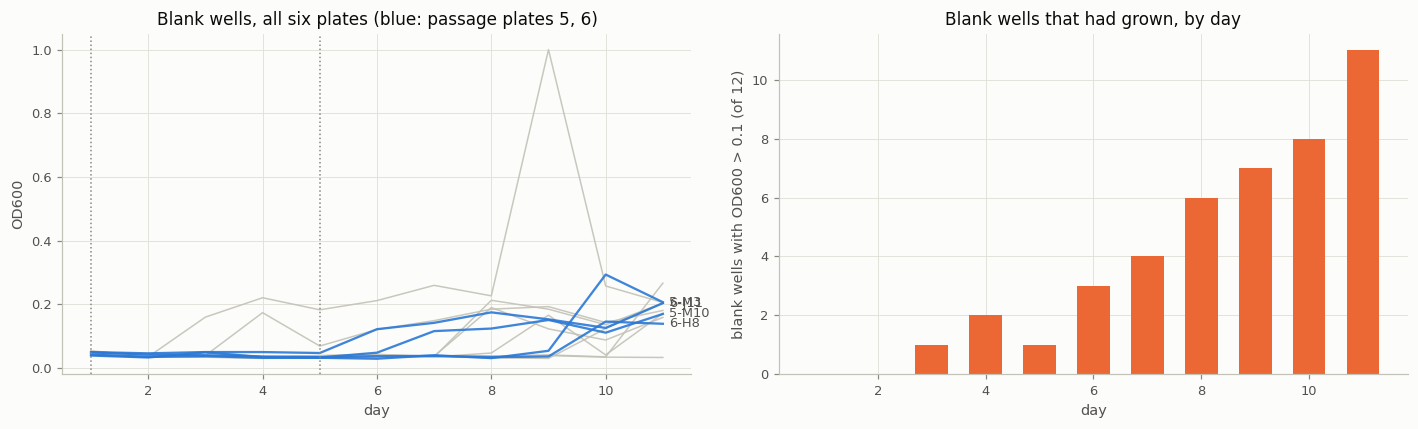

In [22]:
od = pd.read_csv(OUT / "q05_od_daily.csv")
b = od[od.well_type == "blank"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, ((cp, wl), g) in enumerate(b.groupby(["culture_plate", "well"])):
    col = P.CAT[0] if cp in (5, 6) else P.AXIS
    ax[0].plot(g.day, g.od, color=col, lw=1.5 if cp in (5, 6) else 1, alpha=.9)
    if cp in (5, 6):
        P.label_end(ax[0], g.day.iat[-1], g.od.iat[-1], f"{cp}-{wl}")
for d in (1, 5):
    ax[0].axvline(d, color=P.MUTED, ls=":", lw=1)
ax[0].set(xlabel="day", ylabel="OD600", title="Blank wells, all six plates (blue: passage plates 5, 6)")
grown = b.assign(g=b.od > 0.1).groupby("day").g.sum()
ax[1].bar(grown.index, grown.values, color=P.CAT[1], width=.6)
ax[1].set(xlabel="day", ylabel="blank wells with OD600 > 0.1 (of 12)", title="Blank wells that had grown, by day")
fig.tight_layout(); savefig(fig, "01_blank_od.png")
b.pivot_table(index=["culture_plate", "well"], columns="day", values="od").round(2)

Two blanks per plate is little data. By OD, the passage-plate blanks are clean through
d5 and grow from d6–d7 (5-M10, 6-J11) and d10 (5-M3, 6-H8), the trend behind the
contaminated d10 sample; across all six plates 2/12 blanks had grown by d5 and 11/12 by
d11. Sequencing is more sensitive: blank **6-J11 already holds ~2,250 reads at 5 d**
(G4 + A1/A4/A6, the invaders above) while its OD is still 0.05.

At 24 h the blanks did not grow (OD at baseline), and their few reads behave like a
**no-template control**: 5-M3 (115 reads, deep plate) holds K11, M16, L11, I11. These are
strains that are not in plate 5's communities or not in the experiment, i.e. the same
PCR background as section 5a. K11 is the strain missing from all 51 of its own wells,
so its DNA here comes from the background, not from a live K11.

## 6. Per-well flags for downstream analyses

In [23]:
flags = [c for c in fl.columns if c.startswith("flag_") and c != "flag_blank_with_reads"]
s = fl[fl.well_type == "community"].groupby("plate")[flags].mean().mul(100).round(1)
s.index = [f"{p} ({TP[p]})" for p in s.index]
s

,flag_low_depth,flag_external_dna,flag_cross_well,flag_source_co_occupant
5 (plate 5 · 24 h),4.6,0.3,0.7,6.5
6 (plate 6 · 24 h),58.5,22.9,15.0,5.6
9 (plate 5 · 5 d),52.3,23.5,15.0,10.8
10 (plate 6 · 5 d),4.6,4.6,8.5,14.1


`outputs/q04_well_flags.csv` holds every flag per well:

| flag | rule |
|---|---|
| `flag_low_depth` | < 100 called reads |
| `flag_external_dna` | ≥ 10% of called reads from never-inoculated strains (called events) |
| `flag_cross_well` | ≥ 5% from strains on this or another culture plate (not a source-well co-occupant) |
| `flag_source_co_occupant` | ≥ 5% from a sequence that travels with one member (M19 / F17 / F14 / G2 …) |
| `flag_blank_with_reads` | blank well with ≥ 20 called reads |

Member compositions in notebooks 02 and 03 use **member reads only**, so foreign reads
do not distort them. The flags matter where a foreign organism may have *changed* the
community (5 d cross-well transfer, source co-occupants).